# Setup

In [ ]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
sys.path.append(str(Path.cwd().resolve().parent))

import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error

from utils.feature_utils import get_labels

# Helpers

In [ ]:
###  CHANG ME
MODEL_NAME = "rlf"
TEST_DATA_PATH = "YOUR_DATA_DIR"
###

REFORMATTED_PARAM_NAMES = {
    "alpha": r"$\alpha$",
    "alpha_oneshot": r"$\alpha_{oneshot}$",
    "beta": r"$\beta$",
    "stickiness": r"$\kappa$",
    "eps": r"$\epsilon$",
    "phi": r"$\phi$",
}

N_AGENTS = 500
num_blocks = 12
max_num_trials = 78
filename = f"{TEST_DATA_PATH}.csv"
test_data = pd.read_csv(filename)

In [ ]:
color = ["steelblue", "mediumpurple", "violet"]
palette = {
    "MAP": "mediumpurple",
    "Neural Estimator": "steelblue",
    "MLE": "violet",
    "Ground Truth": "red",
}


def get_all_agents_rmse(y_true, y_pred):
    all_mse = []
    for a, pred in enumerate(y_pred):
        mse = root_mean_squared_error(y_true[a], pred)
        all_mse.append(mse)

    return all_mse


def plot_time_series(axes, d_res, max_trial, mle_res, ids=[]):
    for idx, ax in enumerate(axes.flat):
        id = ids[idx] if len(ids) > 0 else idx
        y_true = d_res[d_res.id == id]["true_q"].to_numpy()
        y_pred = d_res[d_res.id == id]["pred_q"].to_numpy()
        map_pred = (
            mle_res[mle_res.id == id]["pred_q"].to_numpy() if len(mle_res) > 0 else []
        )

        result = {
            "Neural Estimator": y_pred[:max_trial],
            "Ground Truth": y_true[:max_trial],
        }
        if len(map_pred) > 0:
            result["MAP"] = map_pred[:max_trial]

        show_legend = True if idx == 0 else False
        plot_ = sns.lineplot(
            result, ax=ax, legend=show_legend, palette=palette, linewidth=3
        )

        if show_legend:
            sns.move_legend(
                ax,
                "lower center",
                bbox_to_anchor=(0.8, 1.05),
                ncol=3,
                title=None,
                frameon=False,
            )

        ax.set_xlabel("Trial #")
        ax.set_title(f"Agent {id}", fontsize=12)
        for ind, label in enumerate(plot_.get_yticklabels()):
            if ind == 0 or ind == 1.0:  # every 10th label is kept
                label.set_visible(True)
            else:
                label.set_visible(False)
    return axes

# LaseNet

## Load LaseNet results

In [ ]:
### CHANGE ME
ANN_RESULT_DIR = ''
MLE_RESULT_DIR = ''
MAP_RESULT_DIR = ''
###

feature_list = ["r", "r-d", "r-d-a", "r-d-a-p", "r-d-a-p-i-s"]

res = []
for num_agents in [1000, 3000, 9000, 27000]:
    for f in feature_list:
        data = pd.read_csv(f"{ANN_RESULT_DIR}/{f}_A{num_agents}_{MODEL_NAME}.csv")
        data["feature"] = f
        data["id"] = np.repeat(np.arange(500), int(data.shape[0] / 500))
        data["sim_budget"] = num_agents
        res.append(data)

res = pd.concat(res)

## Load MLE/MAP results

In [ ]:
# @title MLE/MAP benchmark
likelihood_res = {"mle": [], "map": []}
for rf in likelihood_res.keys():
    dir = MLE_RESULT_DIR if rf == 'mle' else MAP_RESULT_DIR
    lik_res = pd.read_csv(f"{dir}/{MODEL_NAME}.csv")
    lik_res["id"] = np.repeat(np.arange(500), int(lik_res.shape[0] / 500))

    b_res = lik_res.copy()
    b_res["sq_err"] = (b_res["true_rpe"] - b_res["pred_rpe"]) ** 2
    b_res["abs_err"] = (b_res["true_rpe"] - b_res["pred_rpe"]).abs()

    # Group and aggregate
    lik_errors = (
        b_res.groupby("id")
        .agg(MSE=("sq_err", "mean"), MAE=("abs_err", "mean"))
        .reset_index()
    )

    # Calculate RMSE directly from MSE
    lik_errors["RMSE"] = np.sqrt(lik_errors["MSE"])
    likelihood_res[rf] = lik_errors

In [ ]:
# Calculate MSE and MAE for each row
res["sq_err"] = (res["true_rpe"] - res["pred_rpe"]) ** 2
res["abs_err"] = abs(res["true_rpe"] - res["pred_rpe"])

# Now group by 'id' and 'feature' and calculate the mean of these per-row errors
res_errors = (
    res.groupby(["id", "feature", "sim_budget"])
    .agg(MSE=("sq_err", "mean"), MAE=("abs_err", "mean"))
    .reset_index()
)

# Calculate RMSE by taking the square root of the 'mse' column in res_errors
res_errors["RMSE"] = np.sqrt(res_errors["MSE"])
display(res_errors.head())

,id,feature,sim_budget,MSE,MAE,RMSE
0,0,r,1000,0.058248,0.224356,0.241346
1,0,r,3000,0.059816,0.225964,0.244573
2,0,r,9000,0.061736,0.229989,0.248467
3,0,r,27000,0.052176,0.208347,0.228420
4,0,r-d,1000,0.043915,0.189950,0.209559


## Plot LaseNet vs MLE/MAP

/tmp/ipykernel_1114/2852296320.py:6: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.


0.0513817506778304
0.041904710249387606


/tmp/ipykernel_1114/2852296320.py:6: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.


0.044810679246065174
0.03658186799617361


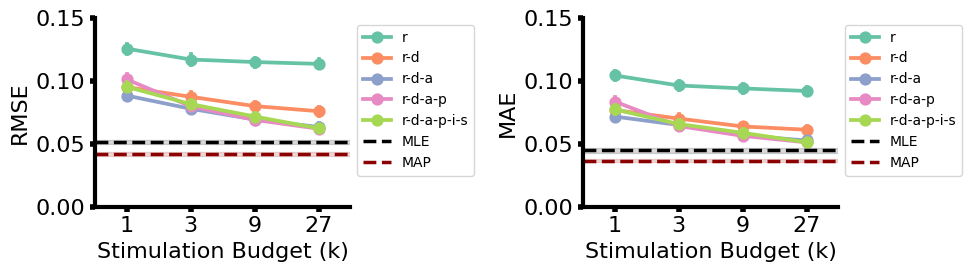

In [ ]:
# @title Summary plot
plt.rcParams.update({"font.size": 16})
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 3))
like_color = {"mle": "black", "map": "darkred"}
for ax, metric in zip(axes, ["RMSE", "MAE"]):
    ax = sns.pointplot(
        data=res_errors,
        x="sim_budget",
        y=metric,
        ax=ax,
        hue="feature",
        palette=sns.color_palette("Set2"),
        estimator="mean",
        errorbar=("ci", 95),
    )

    ax.set_xlabel("Stimulation Budget (k)")
    ax.set(xticks=[0, 1, 2, 3], xticklabels=[1, 3, 9, 27])
    for axis in ["top", "bottom", "left", "right"]:
        ax.spines[axis].set_linewidth(3)
    # # increase tick width
    ax.tick_params(width=4)
    ax.set_ylim(0, 0.15)

    for rf, lik_res in likelihood_res.items():
        lik_mean = lik_res[metric].mean()
        lik_sd = lik_res[metric].sem()
        ax.set_ylim(bottom=0)
        ax.axhline(
            lik_mean,
            color=like_color[rf],
            linestyle="--",
            linewidth=2.5,
            label=rf.upper(),
        )
        ax.axhspan(
            lik_mean - lik_sd, lik_mean + lik_sd, color=like_color[rf], alpha=0.15
        )
        ax.legend(loc="upper right")

    sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=10)

fig.tight_layout()
sns.despine()

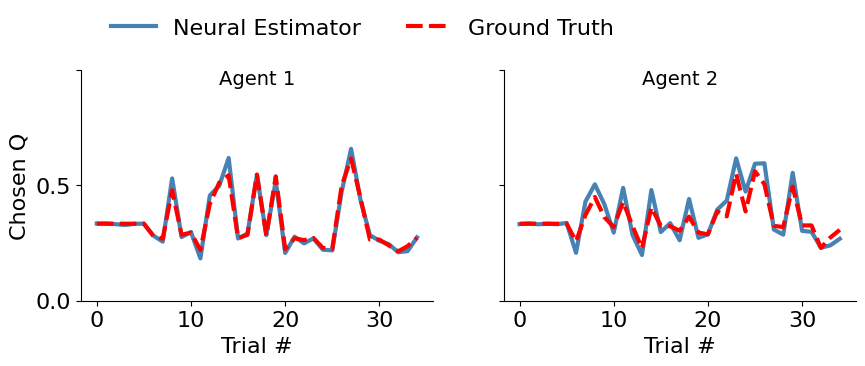

In [ ]:
# @title Time series
plt.rcParams.update({"font.size": 16})

mle_res = likelihood_res['mle']
mle_res["id"] = np.repeat(np.arange(500), int(mle_res.shape[0] / 500))
# # add parameters to title and switch lines
name_to_labels = get_labels(test_data, ["stickiness", "phi", "alpha"])
# Assuming name_to_labels['alpha'] is a NumPy array
alpha_values = name_to_labels["alpha"].ravel()
eps_values = name_to_labels["stickiness"].ravel()
beta_values = name_to_labels["phi"].ravel()
# Find indices where values are greater than 0.65
# indices = np.where((alpha_values < 0.65)) #np.where((alpha_values > 0.78) | (alpha_values < 0.23)) #

# ANN best model
m = "r-d-a"
d_res = res[(res.feature == m) & (res.sim_budget == 27000)]
nrows, n_cols = 1, 2
fig, axes = plt.subplots(
    nrows=nrows, ncols=n_cols, figsize=(n_cols * 5, nrows * 3), sharey=True, sharex=True
)
max_trial = 35  # n_trial*1
axes = plot_time_series(axes, d_res, max_trial, [], [2, 3])

name_to_labels = {"alpha": alpha_values, "stickiness": eps_values, "phi": beta_values}
for idx, ax in enumerate(axes.flat):
    title = ""
    for k, v in name_to_labels.items():
        val = round(v[idx], 2)  # round(v[idx][0], 2)
        title = f"{title}{k}:{val} "

    ax.set_title(f"Agent {idx+1}", size=14, y=0.9)
    ax.set_yticks([0, 0.5, 1])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Chosen Q")

sns.despine()

# Parameter Estimation for RLF

## Load ANN/MLE/MAP results

In [ ]:
### CHANGE ME
ALL_RESULT_PATH = ''
###

param_list = ["alpha", "beta", "phi", "stickiness"]
all_res = pd.read_csv(f"{ALL_RESULT_PATH}.csv")

In [ ]:
likelihood_res = {p: {"mle": [], "map": []} for p in param_list}
for rf in ["mle", "map"]:
    lik_res = all_res[all_res.run_tag == rf]

    b_res = lik_res.copy()
    for p in param_list:
        b_res[f"RMSE_{p}"] = np.sqrt((b_res[f"true_{p}"] - b_res[f"pred_{p}"]) ** 2)
        b_res[f"MAE_{p}"] = (b_res[f"true_{p}"] - b_res[f"pred_{p}"]).abs()

        likelihood_res[p][rf] = b_res[["id", f"RMSE_{p}", f"MAE_{p}"]]

display(likelihood_res[p]["mle"].head())

,id,RMSE_stickiness,MAE_stickiness
0,0,0.039783,0.039783
1,1,0.027619,0.027619
2,2,0.342570,0.342570
3,3,0.164305,0.164305
4,4,0.051300,0.051300


In [ ]:
ann_res = all_res[~all_res.run_tag.isin(["mle", "map"])].copy()
feature_map = {
    "1:rewards": "r",
    "2:+actions": "r-a",
    "3:+prev_action": "r-a-p",
    "4:+stim_iter": "r-a-p-si",
    "5:+delay_stim": "r-a-p-si-d",
    "6:+isswitch": "r-a-p-si-d-i",
}
ann_res["feature"] = ann_res["feature_set"].apply(lambda x: feature_map[x])

all_ann_res = {p: {} for p in param_list}
for p in param_list:
    ann_res[f"sq_err_{p}"] = (ann_res[f"true_{p}"] - ann_res[f"pred_{p}"]) ** 2
    ann_res[f"abs_err_{p}"] = (ann_res[f"true_{p}"] - ann_res[f"pred_{p}"]).abs()

    # Now group by 'id' and 'feature' and calculate the mean of these per-row errors
    res_errors = (
        ann_res.groupby(["id", "feature", "budget"])
        .agg(
            **{
                f"MSE_{p}": (f"sq_err_{p}", "mean"),
                f"MAE_{p}": (f"abs_err_{p}", "mean"),  # Or f'MAE_{p}' if using abs_err
            }
        )
        .reset_index()
    )

    # Calculate RMSE by taking the square root of the 'mse' column in res_errors
    res_errors[f"RMSE_{p}"] = np.sqrt(res_errors[f"MSE_{p}"])

    all_ann_res[p] = res_errors[res_errors.budget > 500]

display(all_ann_res[p].head())

,id,feature,budget,MSE_stickiness,MAE_stickiness,RMSE_stickiness
1,0,r,1000.0,0.020462,0.139148,0.143044
2,0,r,3000.0,0.004536,0.061135,0.067353
3,0,r,9000.0,0.045366,0.179625,0.212992
4,0,r,27000.0,0.016244,0.127450,0.127450
6,0,r-a,1000.0,0.034266,0.181525,0.185111


## Plot ANN vs MLE/MAP

0.09775561839035084
0.07820242924346849
0.1380577154411476
0.09055658738038806
0.028949974752658862
0.019024304695112217
0.09455787458772615
0.07524664412152594
0.09775561839035084
0.07820242924346849
0.1380577154411476
0.09055658738038806
0.028949974752658862
0.019024304695112217
0.09455787458772615
0.07524664412152594


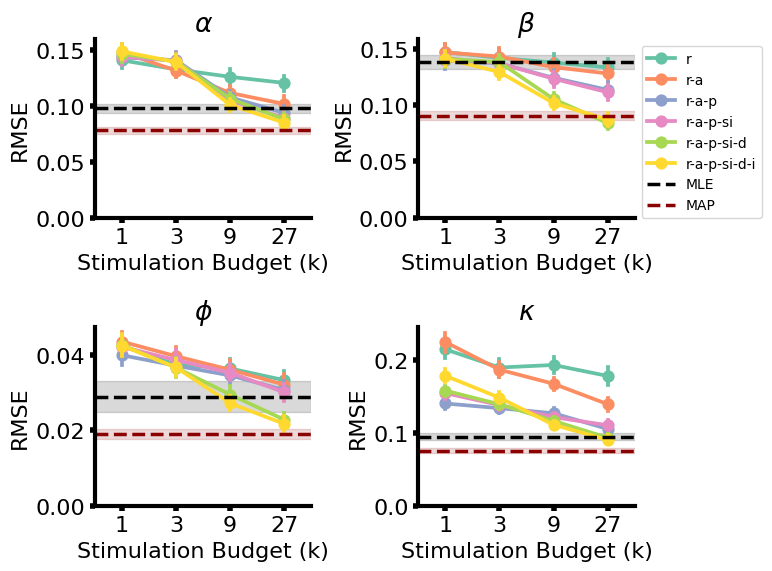

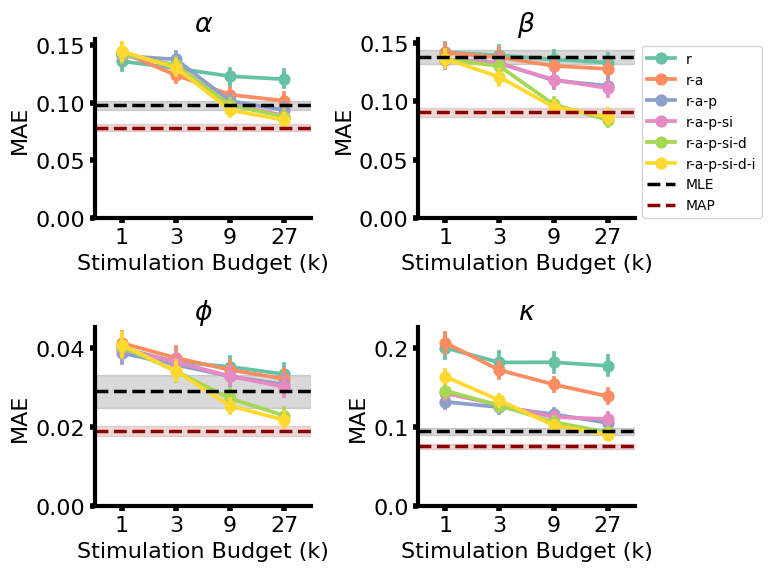

In [ ]:
# @title summary plot

plt.rcParams.update({"font.size": 16})

like_color = {"mle": "black", "map": "darkred"}
for ri, metric in enumerate(["RMSE", "MAE"]):
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(4 * 2, 3 * 2))
    for ci, p in enumerate(param_list):
        show_legend = ci == 1  # len(param_list)-1)
        p_key = f"{metric}_{p}"
        ax = sns.pointplot(
            data=all_ann_res[p],
            x="budget",
            y=p_key,
            ax=axes.flatten()[ci],
            hue="feature",
            palette=sns.color_palette("Set2", 6),
            estimator="mean",
            legend=show_legend,
            errorbar=("ci", 95),
        )
        # ax.set_title(metric)
        ax.set_xlabel("Stimulation Budget (k)")
        ax.set(xticks=[0, 1, 2, 3], xticklabels=[1, 3, 9, 27])
        for axis in ["top", "bottom", "left", "right"]:
            ax.spines[axis].set_linewidth(3)
        # # increase tick width
        ax.tick_params(width=4)
        # ax.set_ylim(0, 0.15)
        ax.set_title(REFORMATTED_PARAM_NAMES[p])

        for rf, lik_res in likelihood_res[p].items():
            # Draw line
            # 2. Draw MLE flat line + SD band per feature (or globally)
            lik_mean = lik_res[p_key].mean()
            lik_sd = lik_res[p_key].sem()
            ax.set_ylim(bottom=0)
            # Draw line
            ax.axhline(
                lik_mean,
                color=like_color[rf],
                linestyle="--",
                linewidth=2.5,
                label=rf.upper(),
            )
            print(lik_mean)
            # Draw SD shaded area across the plot
            ax.axhspan(
                lik_mean - lik_sd, lik_mean + lik_sd, color=like_color[rf], alpha=0.15
            )
            #

        if show_legend:
            ax.legend(loc="upper right")
            sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=10)

        ax.set_ylabel(metric)

    fig.tight_layout(w_pad=1)
    sns.despine()

In [ ]:
# @title Correlation plots
from sklearn.metrics import r2_score

def add_corr_scores(ax, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    ax.text(
        0.1,
        0.9,
        "$R^2$ = {:.3f}".format(r2),
        horizontalalignment="left",
        verticalalignment="center",
        color="black",
        fontweight="heavy",
        transform=ax.transAxes,
        size=12,
    )

    corr = np.corrcoef(y_true, y_pred)[0, 1]
    ax.text(
        0.1,
        0.8,
        "$r$ = {:.3f}".format(corr),
        horizontalalignment="left",
        verticalalignment="center",
        color="black",
        transform=ax.transAxes,
        size=12,
    )

    return ax


best_res = ann_res[(ann_res.run_tag == "YOUR_RUN_TAG")].copy()
map_res = all_res[all_res.run_tag == "map"].copy()
mle_res = all_res[all_res.run_tag == "mle"].copy()
color = ["steelblue", "mediumpurple", "violet"]
for mi, (title, res) in enumerate(
    [("Neural Estimator", best_res), ("MAP", map_res), ("MLE", mle_res)]
):
    n_row, n_col = 1, len(param_list)
    f, axarr = plt.subplots(n_row, n_col, figsize=(3 * n_col, 3 * n_row))
    for i, p in enumerate(param_list):
        true_l, dl_l = f"true_{p}", f"pred_{p}"
        ax = axarr.flat[i]
        ax = sns.regplot(
            data=res,
            ci=99,
            scatter_kws={
                "s": 15,  # Size of the circle
                "facecolors": "none",  # Makes the center hollow/transparent
            },
            x=true_l,
            y=dl_l,
            ax=ax,
            color=color[mi],
            line_kws=dict(color="r"),
        )

        ax.plot(
            [ax.get_xlim()[0], ax.get_xlim()[1]],
            [ax.get_xlim()[0], ax.get_xlim()[1]],
            color="black",
            alpha=0.9,
            linestyle="dashed",
        )
        ax = add_corr_scores(ax, res[true_l], res[dl_l])

        ax.set_title(REFORMATTED_PARAM_NAMES[p], fontsize=14)
        ax.set_xlabel("Groud truth", fontsize=12)
        ax.set_ylabel(title, fontsize=12)

    f.tight_layout(w_pad=1)
    sns.despine()

# Parameter Estimation for NoisyRL

In [ ]:
## CHANGE ME
ALL_RESULT_PATH= ""
###

REFORMATTED_PARAM_NAMES = {
    "alpha_c": r"$\alpha_c$",
    "alpha_u": r"$\alpha_u$",
    "xi": r"$\kappa$",
    "epsilon": r"$\epsilon$",
}

param_list = ["alpha_c", "alpha_u", "epsilon", "xi"]
all_res = pd.read_csv(f"{ALL_RESULT_PATH}.csv")

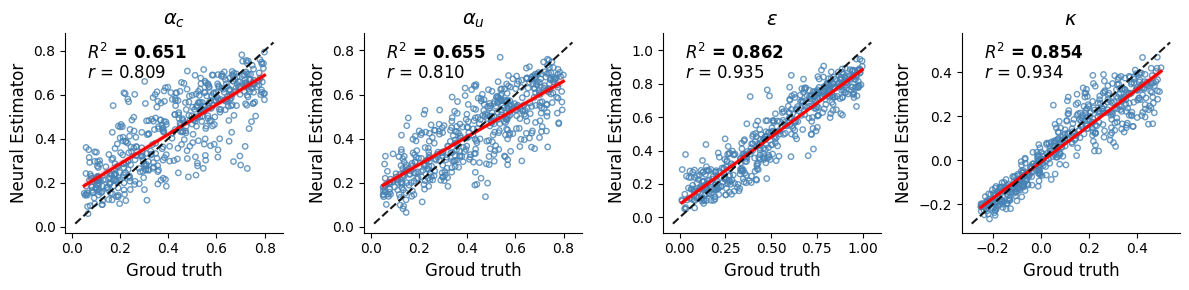

In [ ]:
res = all_res[
    (all_res.model == "BEST_MODEL")
    & (all_res.n_features == 4)
    & (all_res.init_seed == 11)
].copy()

title = "Neural Estimator"
color = ["steelblue", "mediumpurple", "violet"]
n_row, n_col = 1, len(param_list)
f, axarr = plt.subplots(n_row, n_col, figsize=(3 * n_col, 3 * n_row))
for i, p in enumerate(param_list):
    true_l, dl_l = f"true_{p}", f"pred_{p}"
    ax = axarr.flat[i]
    ax = sns.regplot(
        data=res,
        ci=99,
        scatter_kws={
            "s": 15,  # Size of the circle
            "facecolors": "none",  # Makes the center hollow/transparent
        },
        x=true_l,
        y=dl_l,
        ax=ax,
        color=color[0],
        line_kws=dict(color="r"),
    )

    ax.plot(
        [ax.get_xlim()[0], ax.get_xlim()[1]],
        [ax.get_xlim()[0], ax.get_xlim()[1]],
        color="black",
        alpha=0.9,
        linestyle="dashed",
    )
    ax = add_corr_scores(ax, res[true_l], res[dl_l])

    ax.set_title(REFORMATTED_PARAM_NAMES[p], fontsize=14)
    ax.set_xlabel("Groud truth", fontsize=12)
    ax.set_ylabel(title, fontsize=12)

f.tight_layout(w_pad=1)
sns.despine()


# Model identification

In [ ]:
from sklearn.metrics import confusion_matrix

### CHANGE ME
ANN_RESULT_PATH = ''
MAP_RESULT_PATH = ''
###

## Load MAP result

In [ ]:
# @title AIC accuracy
from sklearn.metrics import classification_report

map_res = pd.read_csv(f"{MAP_RESULT_PATH}.csv")
best_fit = (
    map_res.sort_values(["data_model", "id", "aic"])
    .groupby(["data_model", "id"], as_index=False)
    .first()[["id", "fit_model", "data_model", "aic", "bic"]]
)

y_true = best_fit.data_model.to_list()
y_pred = best_fit.fit_model.to_list()
map_acc = classification_report(y_true, y_pred, output_dict=True)["accuracy"]
map_acc

0.959

## Load ANN results

In [ ]:
def calculate_group_accuracy(group):
    y_true_group = group["y_true"]
    y_pred_group = group["y_pred"]
    # Ensure y_true_group and y_pred_group are not empty to avoid errors
    if not y_true_group.empty and not y_pred_group.empty:
        accuracy = classification_report(y_true_group, y_pred_group, output_dict=True)[
            "accuracy"
        ]
    else:
        accuracy = None  # Or np.nan, or handle as appropriate for empty groups
    return pd.Series({"accuracy": accuracy})


all_mi_res = pd.read_csv(f"{ANN_RESULT_PATH}.csv")
ann_res = all_mi_res.copy()
feature_map = {1: "p", 2: "p-r", 3: "p-r-a", 4: "p-r-a-d", 6: "p-r-a-d-i-s"}
ann_res["feature"] = ann_res["n_features"].apply(lambda x: feature_map[x])

res_acc = (
    ann_res.groupby(["feature", "budget", "seed"])
    .apply(calculate_group_accuracy)
    .reset_index()
)

# Display the head of the new DataFrame with accuracy
display(res_acc.head())

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
/usr/local/lib/python3.1

,feature,budget,seed,accuracy
0,p,1000,1553,0.489
1,p,1000,5144,0.500
2,p,1000,17544,0.513
3,p,3000,1553,0.511
4,p,3000,5144,0.494


## Plot ANN vs. AIC

/tmp/ipykernel_1645/1498247100.py:6: UserWarning: The palette list has more values (8) than needed (5), which may not be intended.


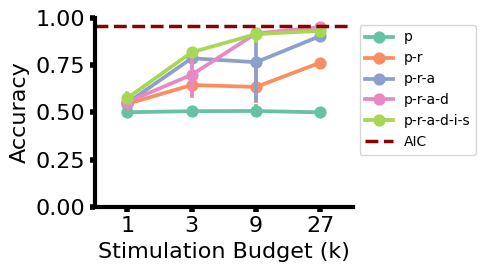

In [ ]:
plt.rcParams.update({"font.size": 16})
fig, axes = plt.subplots(nrows=1, ncols=1, figsize=(5, 3))
like_color = {"AIC": "darkred"}
metric = "accuracy"
ax = sns.pointplot(
    data=res_acc,
    x="budget",
    y=metric,
    ax=axes,
    hue="feature",
    palette=sns.color_palette("Set2"),
    estimator="mean",
    errorbar=("ci", 95),
)

ax.set_xlabel("Stimulation Budget (k)")
ax.set(xticks=[0, 1, 2, 3], xticklabels=[1, 3, 9, 27])
for axis in ["top", "bottom", "left", "right"]:
    ax.spines[axis].set_linewidth(3)
# # increase tick width
ax.tick_params(width=4)
ax.set_ylim(0, 1)

ax.set_ylim(bottom=0)
# Draw line
ax.axhline(map_acc, color=like_color["AIC"], linestyle="--", linewidth=2.5, label="AIC")
ax.legend(loc="upper right")
ax.set_ylabel("Accuracy")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1), fontsize=10)
sns.despine()
fig.tight_layout()

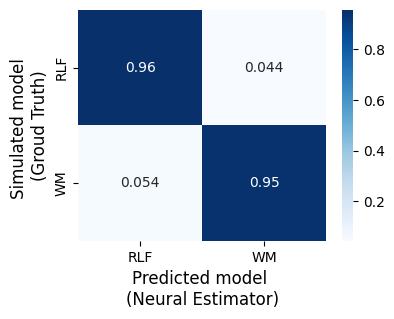

In [ ]:
best_res = all_mi_res[all_mi_res.run_tag == "BEST_MODEL"].copy()
num_test_agents = len(test_data.agentid.unique())

cf_matrix = confusion_matrix(best_res.y_true, best_res.y_pred)

model_list = all_mi_res.model_type.unique().tolist()
fig = plt.figure(figsize=(4, 3))
ax = sns.heatmap(
    cf_matrix / num_test_agents,
    annot=True,
    cmap="Blues",
    xticklabels=model_list,
    yticklabels=model_list,
)

# ax.set(xlabel='Predicted model (Neural Estimator)', ylabel='Simulated model (Groud Truth)', title='', fontsize=14)
ax.set_xlabel("Predicted model \n(Neural Estimator)", fontsize=12)
ax.set_ylabel("Simulated model \n(Groud Truth)", fontsize=12)